In [1]:
import pandas as pd

df = pd.read_csv('wavelet.csv')

In [2]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,844246.771846,766322.702933,676362.874956,582653.055304,487632.724253,393843.605076,305121.373537,223931.271079,154857.408559,94572.790876,...,93226.921534,153166.942791,222545.054532,303888.999399,391866.465254,486724.818599,582024.721112,676678.812110,766812.986354,0.0
1,851375.348222,774111.417021,683931.984637,589071.573066,493228.136977,398480.843524,308753.153052,226674.010000,156393.591442,95865.394673,...,93312.556147,153424.613589,223178.694361,305063.310803,394014.921374,489715.817570,586245.862100,681382.519576,772321.154907,0.0
2,884561.046834,805462.679879,712995.277572,616338.739829,518113.814785,420973.478929,328356.639683,243127.911778,169764.937039,105944.804686,...,90432.600876,151332.371735,222692.063303,307100.479375,399330.775529,498983.142903,599785.024406,699926.556974,796329.385742,0.0
3,875623.235671,791263.938793,693748.534380,592467.523342,491291.727575,392664.217563,300174.393228,216875.012549,146730.350371,86788.007042,...,108194.982183,172722.918894,246321.839503,331850.274237,423853.145715,521895.203145,620060.792082,716353.006580,807798.021463,0.0
4,862933.383222,782687.639338,689386.984217,592237.854560,493949.114379,397407.064741,306431.404397,223540.773615,153226.074482,92582.391814,...,98969.366795,160784.411899,231720.006889,314865.545939,404502.003237,500760.392064,597458.846946,693382.098300,785308.674817,0.0


In [3]:
df.shape

(4662, 26)

In [5]:
selected_data = df[df["25"].isin([0, 1, 2, 3, 4])]


In [7]:
selected_data.shape

(4149, 26)

In [8]:
import joblib

save_dir = './models/'

gmm_models = []
for i in range(5):
    model_filename = f'gmm_model_{i}.pkl'
    model_path = save_dir + model_filename
    loaded_gmm_model = joblib.load(model_path)
    gmm_models.append(loaded_gmm_model)

In [9]:
X = selected_data.drop(columns=['25'])

y = selected_data['25']

In [10]:
import numpy as np

predicted_probs = np.zeros((len(X), 5))
for i in range(5):
    predicted_probs[:, i] = gmm_models[i].score_samples(X)

In [11]:
predicted_labels = np.argmax(predicted_probs, axis=1)

In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y, predicted_labels)
print(f"Accuracy: {accuracy:.2f}")


Accuracy: 0.76


In [13]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4:
		return 0
	elif prediction == 5:
		return 1
	else:
		return 2

In [14]:
y_pred_mapped = [predictionMapping(prediction) for prediction in predicted_labels]


y_val_mapped = y.apply(predictionMapping)

In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_val_mapped, y_pred_mapped)
print(f"Accuracy: {accuracy:.2f}")


Accuracy: 0.93


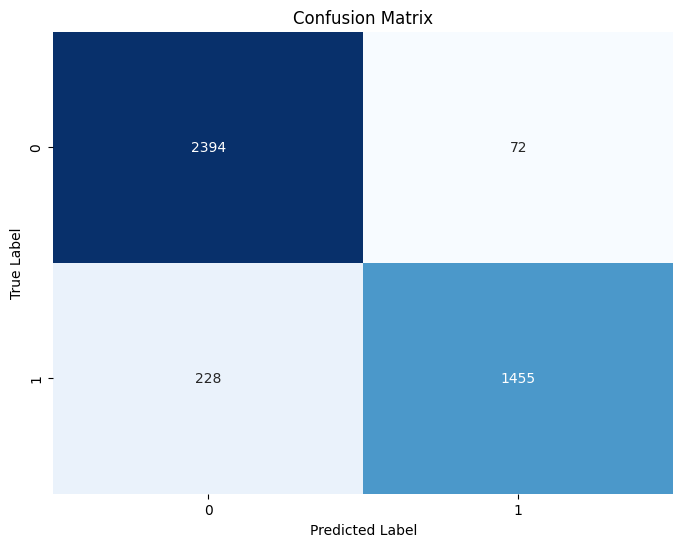

In [18]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val_mapped, y_pred_mapped)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [20]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val_mapped, y_pred_mapped, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.9270


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val_mapped, y_pred_mapped, average=None)
recall = recall_score(y_val_mapped, y_pred_mapped, average=None)
f1 = f1_score(y_val_mapped, y_pred_mapped, average=None)

# Print results for each class
for class_label in range(2):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.9130
Recall: 0.9708
F1 Score: 0.9410

Class 1:
Precision: 0.9528
Recall: 0.8645
F1 Score: 0.9065

